# 02 — Do points that run ahead of xPTS stay ahead?

**The question.** Some clubs collect more points than their chances deserved, and
some fewer. Does that gap *persist* — is it a property of the club that carries
into the next stretch of matches — or does it wash out? And when you want to know
what a club will do next, is its points tally the best thing to look at, or does
its expected-goals difference tell you something the table does not?

**Why it matters.** This is the argument every xG conversation turns into. If
overperformance persists, it is a skill worth paying for and the table is the
better guide. If it washes out, then a club sitting above its expected points is
sitting on borrowed time, and anyone reading the table alone will be surprised
when the correction arrives. The answer decides which number you should look at
first — and the same question, asked about unseen matches rather than about what
already happened, is where Part 3 begins.

**What this notebook does not do.** It does not predict. Everything here is
measured on matches that have already been played, and every claim is an
association. A genuine forecast needs a train/test split and belongs in Part 3
(CLAUDE.md §7).

## How to read this

Every number is computed live from the dbt marts named in the next cell, which are
built from a pinned Gold snapshot. Nothing is typed in by hand.

The notebook runs against whatever `GOLD_SNAPSHOT_DIR` points at: the full
warehouse export locally, and the tiny synthetic fixture in CI. So the **committed
outputs are the real snapshot** — CI only re-executes the notebook to prove the
code still runs, and its numbers are not meaningful.

In [1]:
import sys
from pathlib import Path

# The repository's shared code lives in src/, next to this notebooks/ folder.
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm

from football_analytics import marts, viz
from football_analytics import stats as st

viz.apply_style()
pd.set_option("display.width", 200)

m = marts.open_marts()
CITATION = m.citation()
print(CITATION)

dbt marts built from the Gold snapshot exported 2026-09-20T13:41:36+00:00, matches 2024-08-15 to 2026-09-19 (3,733 matches, 115,410 player events, 94,034 shots)


## The sample

A half-season comparison only means something in a **completed** season: the
in-progress one has a first half and a partial second, which would read as a
collapse in form for every club in it. `mart_team_season_half` carries
`is_season_complete` for exactly this filter (CLAUDE.md §6), and the halves are cut
by **match number per club**, not by date — clubs play the same number of matches
but not on the same days, so a calendar cut-off would put a different number of
fixtures either side for different clubs.

In [2]:
halves = m.df(
    """
    SELECT team_key, team_name, season, competition_code, season_half,
           played, points, xpts, points_minus_xpts, xg_difference,
           matches_with_xpts, matches_with_xg
    FROM mart_team_season_half
    WHERE is_season_complete
    ORDER BY season, competition_code, team_name, season_half
    """
)

# One row per club-season, with each half's figures side by side.
paired = halves.pivot_table(
    index=["team_key", "team_name", "season", "competition_code"],
    columns="season_half",
    values=["played", "points", "xpts", "points_minus_xpts", "xg_difference"],
)
paired.columns = [f"{name}_h{half}" for name, half in paired.columns]
paired = paired.reset_index()

print(f"{len(paired)} club-seasons, {paired.season.nunique()} complete season(s), "
      f"{paired.competition_code.nunique()} leagues")
print(f"matches per half: {halves.played.min():.0f} to {halves.played.max():.0f}")
halves.groupby(["season", "competition_code"]).agg(
    clubs=("team_name", "nunique"), rows=("team_name", "size")
)

192 club-seasons, 2 complete season(s), 5 leagues
matches per half: 17 to 19


clubs  rows
season  competition_code             
2024/25 BL1                  18    36
        FL1                  18    36
        PD                   20    40
        PL                   20    40
        SA                   20    40
2025/26 BL1                  18    36
        FL1                  18    36
        PD                   20    40
        PL                   20    40
        SA                   20    40

## 1. Who ran ahead of their expected points?

Over a full season first, to see the size of the effect before asking whether it
lasts. `points_minus_xpts` compares points with expected points **over the same
matches** — the ones that carry an xPTS — because a null xG means the two sources
never paired that fixture, and scoring it as zero would invent an overperformance
out of a missing match (CLAUDE.md §5, trap 7).

In [3]:
season_table = m.df(
    """
    SELECT team_name, season, competition_code, played, points,
           round(xpts, 1)              AS xpts,
           round(points_minus_xpts, 1) AS points_minus_xpts,
           round(xg_difference, 1)     AS xg_difference,
           matches_with_xpts, table_position
    FROM mart_team_season
    WHERE is_season_complete
    ORDER BY points_minus_xpts DESC
    """
)

extremes = pd.concat([season_table.head(5), season_table.tail(5)])
print(f"spread of points - xPTS across {len(season_table)} club-seasons: "
      f"{season_table.points_minus_xpts.min():+.1f} to "
      f"{season_table.points_minus_xpts.max():+.1f}")
extremes

spread of points - xPTS across 192 club-seasons: -21.1 to +16.0


,team_name,season,competition_code,played,points,xpts,points_minus_xpts,xg_difference,matches_with_xpts,table_position
0,Rennes,2025/26,FL1,34,59.0,43.0,16.0,-6.1,33,6
1,Nottingham Forest,2024/25,PL,38,65.0,50.0,15.0,-3.2,38,7
2,Barcelona,2025/26,PD,38,94.0,79.1,14.9,49.0,38,1
3,Aston Villa,2025/26,PL,38,65.0,51.1,13.9,-0.5,38,4
4,Strasbourg,2024/25,FL1,34,57.0,43.4,13.6,-8.0,34,7
187,Toulouse,2024/25,FL1,34,42.0,56.5,-14.5,15.5,34,10
188,Wolverhampton Wanderers,2025/26,PL,38,20.0,35.4,-15.4,-29.9,38,20
189,Real Valladolid,2024/25,PD,38,16.0,31.7,-15.7,-40.9,38,20
190,Hellas Verona,2025/26,SA,38,21.0,41.0,-20.0,-18.2,38,19
191,Pisa,2025/26,SA,38,18.0,39.1,-21.1,-24.3,38,20


The spread is wide enough to matter: the extremes are worth more than a
Champions League place. The whole question is whether a club at either end of this
table is *revealing* something or just having a run.

## 2. Does the gap persist from one half of a season to the next?

The direct test. If overperformance is a property of a club, a club that
overperformed in its first 19 matches should overperform in its next 19.

In [4]:
persistence = st.correlation_ci(
    paired.points_minus_xpts_h1, paired.points_minus_xpts_h2
)
print(f"first-half gap vs second-half gap:  r = {persistence}")
print(f"interval excludes zero: {persistence.excludes_zero}")

first-half gap vs second-half gap:  r = +0.134 (95% CI +0.002 to +0.268, n = 192), p = 0.063
interval excludes zero: True


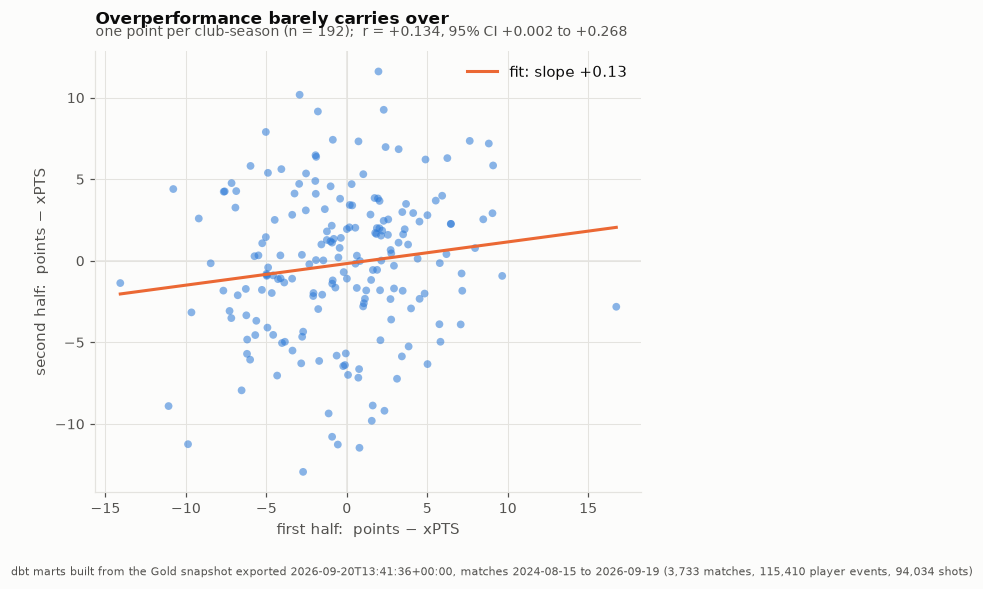

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))

ax.axhline(0, color=viz.GRID, lw=1, zorder=1)
ax.axvline(0, color=viz.GRID, lw=1, zorder=1)
ax.scatter(
    paired.points_minus_xpts_h1, paired.points_minus_xpts_h2,
    s=26, color=viz.ACCENT, alpha=0.55, edgecolor="none", zorder=3,
)

# The fitted line, drawn only to show how flat it is.
fit = sm.OLS(
    paired.points_minus_xpts_h2, sm.add_constant(paired[["points_minus_xpts_h1"]])
).fit()
xs = pd.Series([paired.points_minus_xpts_h1.min(), paired.points_minus_xpts_h1.max()])
ax.plot(xs, fit.params.iloc[0] + fit.params.iloc[1] * xs,
        color=viz.GOAL, lw=2, zorder=4,
        label=f"fit: slope {fit.params.iloc[1]:+.2f}")

ax.set_xlabel("first half:  points − xPTS")
ax.set_ylabel("second half:  points − xPTS")
ax.legend(loc="upper right")
viz.title_block(
    ax,
    "Overperformance barely carries over",
    f"one point per club-season (n = {len(paired)});  r = {persistence.value:+.3f}, "
    f"95% CI {persistence.low:+.3f} to {persistence.high:+.3f}",
)
viz.annotate_source(ax, CITATION)
plt.show()

**The relationship is close to nothing.** The cloud is round, the fitted line
is nearly flat, and the confidence interval on the correlation reaches zero. Knowing
that a club took more points than its chances deserved before Christmas tells you
almost nothing about whether it will do so afterwards.

That is the first half of the answer, and it is worth being careful about what it
is not. A correlation near zero does not mean finishing or game management are
imaginary — it means that whatever of them is real is small next to the noise in
half a season of football, which is 19 matches.

## 3. What happens to the clubs at the extremes?

A correlation is a summary of the whole cloud. The more concrete question is what
became of the clubs that were furthest ahead: extreme performers in one period
drift back towards average in the next, and that is worth measuring directly
rather than assuming (CLAUDE.md §7).

Quintiles of first-half gap, then what each group did in its second half.

In [6]:
# duplicates="drop" so this also runs on the tiny CI fixture, where there are
# fewer club-seasons than quintiles.
paired["first_half_group"] = pd.qcut(
    paired.points_minus_xpts_h1, 5,
    labels=["most under", "under", "average", "over", "most over"],
    duplicates="drop",
)

groups = paired.groupby("first_half_group", observed=True).agg(
    clubs=("team_name", "size"),
    gap_h1=("points_minus_xpts_h1", "mean"),
    gap_h2=("points_minus_xpts_h2", "mean"),
    points_h1=("points_h1", "mean"),
    points_h2=("points_h2", "mean"),
).round(2)
groups

,clubs,gap_h1,gap_h2,points_h1,points_h2
first_half_group,,,,,
most under,39,-6.76,-0.89,17.79,22.62
under,38,-2.82,-0.03,20.89,23.63
average,38,-0.26,-1.14,22.97,23.13
over,38,2.00,0.11,29.63,27.89
most over,39,5.88,0.85,33.74,28.38


In [7]:
top = paired[paired.first_half_group == "most over"]
bottom = paired[paired.first_half_group == "most under"]

# Printed in one go: consecutive print() calls get split into stdout chunks
# unpredictably, which makes an identical re-run produce a different notebook file.
print("\n".join([
    "Biggest first-half OVERperformers",
    f"  gap    {st.mean_difference_ci(top.points_minus_xpts_h1, top.points_minus_xpts_h2)}",
    f"  points {st.mean_difference_ci(top.points_h1, top.points_h2)}",
    "",
    "Biggest first-half UNDERperformers",
    f"  gap    {st.mean_difference_ci(bottom.points_minus_xpts_h1, bottom.points_minus_xpts_h2)}",
    f"  points {st.mean_difference_ci(bottom.points_h1, bottom.points_h2)}",
]))

Biggest first-half OVERperformers
  gap    -5.031 (95% CI -6.484 to -3.679, n = 39)
  points -5.359 (95% CI -7.026 to -3.769, n = 39)

Biggest first-half UNDERperformers
  gap    +5.870 (95% CI +4.537 to +7.283, n = 39)
  points +4.821 (95% CI +2.615 to +7.103, n = 39)


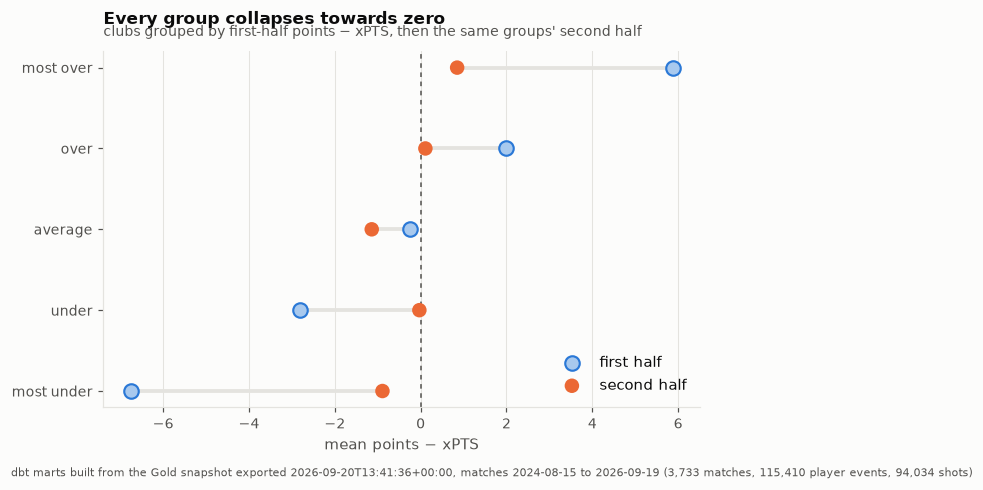

In [8]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))

order = list(groups.index)
ypos = range(len(order))
for y, name in zip(ypos, order, strict=True):
    h1, h2 = groups.loc[name, "gap_h1"], groups.loc[name, "gap_h2"]
    ax.plot([h1, h2], [y, y], color=viz.GRID, lw=2.5, solid_capstyle="round", zorder=2)
    ax.scatter([h1], [y], s=90, color=viz.ACCENT_SOFT, edgecolor=viz.ACCENT,
               lw=1.4, zorder=3, label="first half" if y == 0 else None)
    ax.scatter([h2], [y], s=90, color=viz.GOAL, edgecolor="none",
               zorder=4, label="second half" if y == 0 else None)

ax.axvline(0, color=viz.INK_MUTED, lw=1, ls=(0, (3, 3)), zorder=1)
ax.set_yticks(list(ypos), order)
ax.set_xlabel("mean points − xPTS")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.title_block(
    ax,
    "Every group collapses towards zero",
    "clubs grouped by first-half points − xPTS, then the same groups' second half",
)
viz.annotate_source(ax, CITATION)
plt.show()

**Both tails come almost all the way back.** The biggest overperformers give
up nearly their whole advantage, the biggest underperformers recover nearly all of
theirs, and the intervals on both movements are comfortably clear of zero.

Note what the points columns in the table above show: this is not only a
bookkeeping change in the gap. The overperforming group's actual points *fell*,
and the underperformers' actual points *rose*. The correction shows up in the
league table, not just in the xG column.

Two cautions. Regression to the mean is partly a statistical artefact — pick the
extremes of any noisy measure and they will look less extreme next time, whatever
the underlying truth. And these groups are not random: a club that overperformed
may also be good, so some of what looks like decline is simply the sample
returning to its own average.

## 4. So what should you read — points, or expected goals?

Three candidates from the first half, each measured against the same outcome:
second-half points. Correlations first, then the comparison that actually settles
it.

In [9]:
candidates = {
    "first-half points": "points_h1",
    "first-half xPTS": "xpts_h1",
    "first-half xG difference": "xg_difference_h1",
}
print("\n".join(
    f"  {label:26s} vs second-half points:  {st.correlation_ci(paired[column], paired.points_h2)}"
    for label, column in candidates.items()
))

  first-half points          vs second-half points:  +0.694 (95% CI +0.611 to +0.764, n = 192), p = 0.000
  first-half xPTS            vs second-half points:  +0.727 (95% CI +0.653 to +0.788, n = 192), p = 0.000
  first-half xG difference   vs second-half points:  +0.722 (95% CI +0.649 to +0.781, n = 192), p = 0.000


All three are strong and they look ordered — but they are measured on the same
192 club-seasons, so their intervals overlap and cannot be compared by eye. The
honest comparison resamples the clubs and recomputes **both** correlations on each
resample, giving an interval on the *difference*.

In [10]:
lines = []
for label, better, baseline in [
    ("xPTS over points", "xpts_h1", "points_h1"),
    ("xG difference over points", "xg_difference_h1", "points_h1"),
]:
    delta = st.paired_correlation_difference_ci(
        paired[better], paired[baseline], paired.points_h2
    )
    verdict = "distinguishable" if delta.excludes_zero else "NOT distinguishable"
    lines.append(f"  {label:28s} Δr = {delta}  →  {verdict}")
print("\n".join(lines))

  xPTS over points             Δr = +0.033 (95% CI -0.017 to +0.083, n = 192)  →  NOT distinguishable
  xG difference over points    Δr = +0.027 (95% CI -0.021 to +0.076, n = 192)  →  NOT distinguishable


**Head to head, neither expected-goals measure beats points.** Both differences
are positive, both are small, and both intervals contain zero. On this sample you
cannot say that xPTS or xG difference is the better single number to read.

That is a more interesting result than a clean win would have been, and it is not
the same as saying xG adds nothing. The right question is not "which one" but
"does either carry information the other lacks" — which is a regression, not a
correlation.

In [11]:
model = sm.OLS(
    paired.points_h2, sm.add_constant(paired[["points_h1", "xg_difference_h1"]])
).fit()
points_only = sm.OLS(
    paired.points_h2, sm.add_constant(paired[["points_h1"]])
).fit()

print(model.summary().tables[1])
print(f"\nR² with points alone           {points_only.rsquared:.3f}")
print(f"R² with points + xG difference {model.rsquared:.3f}")
print(f"added by xG difference         {model.rsquared - points_only.rsquared:+.3f}")

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               18.3438      2.423      7.572      0.000      13.565      23.123
points_h1            0.2716      0.095      2.853      0.005       0.084       0.459
xg_difference_h1     0.3557      0.072      4.916      0.000       0.213       0.498

R² with points alone           0.482
R² with points + xG difference 0.541
added by xG difference         +0.059


**Both terms stand up.** With first-half points already in the model, first-half
xG difference still carries a clearly non-zero coefficient, and explained variance
in second-half points rises appreciably. The reverse also holds — points do not
become redundant.

So the two numbers are not rivals. They describe overlapping but different things,
and a club's next 19 matches are better described by both together than by either
alone.

Read with the usual care for a regression on observational data: these
coefficients describe how the quantities moved together across 192 club-seasons,
not what would happen if a club somehow changed its xG difference while holding
its points fixed.

## The answer

**Does overperformance against xPTS persist? Essentially no.** Across 192
club-seasons from two complete big-5 seasons, the correlation between a club's
first-half and second-half points-over-xPTS gap is +0.13, with a 95% interval that
reaches zero. The clubs furthest ahead of their expected points before the halfway
mark gave up almost all of that advantage afterwards — around five points of gap,
and around five points of *actual* points — and the clubs furthest behind recovered
by a similar amount. A club sitting well above its expected points is, on this
evidence, far more likely to be enjoying a run than displaying a trait.

**Does xG difference tell you more than the table? Not on its own — but yes
alongside it.** As a single number, first-half xG difference and first-half xPTS
are each about as informative about second-half points as first-half points are;
the differences are small and not distinguishable from zero on this sample. But
once first-half points are accounted for, first-half xG difference still adds
clearly to how well second-half points are described. The practical reading: the
table tells you what a club has collected, xG difference tells you something
further about how it has played, and you want both.

### Caveats

- **Two complete seasons, 192 club-seasons.** Enough to see a near-zero
  correlation clearly; not enough to rule out a small persistent effect, and not
  enough to say much league by league — per-league correlations range from +0.03 to
  +0.20 and none is individually distinguishable from zero at n ≈ 40.
- **Half a season is 17–19 matches.** Short. Some of the non-persistence measured
  here is simply how noisy a 19-match sample of football is, which is a limit on
  the method rather than a fact about clubs.
- **Nothing here is causal.** These are associations between quantities measured on
  matches that were already played.
- **Regression to the mean cuts both ways.** It is the finding in section 3, and it
  is also partly an artefact of selecting extremes; both readings are true at once.
- **xPTS and xG are Understat's**, with Understat's model behind them. Twelve
  fixtures in the snapshot carry no xG at all, and every figure here is computed
  over the matches that do, with the coverage stated in the marts (CLAUDE.md §5,
  trap 7).
- **Expected points are not the only lens.** A club can beat its xPTS through
  finishing, goalkeeping, game state, or luck, and this notebook does not separate
  them. Whether *finishing* specifically is a repeatable skill is the next
  question, in `03_is_finishing_repeatable.ipynb`.

**What comes next.** This analysis stops at description. Turning "xG difference
adds information about the next half-season" into a forecast of unseen matches —
with a train/test split, and held to a baseline — is Part 3.